**1. Import Libraries**

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


**2. Load the datasets**

In [5]:
apps = pd.read_csv("googleplaystore.csv")
reviews = pd.read_csv("googleplaystore_user_reviews.csv")

print("Apps Dataset Shape:", apps.shape)
print("Reviews Dataset Shape:", reviews.shape)

Apps Dataset Shape: (10841, 13)
Reviews Dataset Shape: (64295, 5)


**3. Inspect the apps dataset**

In [6]:
apps.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [7]:
apps.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


**4. Inspecting the reviews dataset**

In [8]:
reviews.head()

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


In [9]:
reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64295 entries, 0 to 64294
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   App                     64295 non-null  object 
 1   Translated_Review       37427 non-null  object 
 2   Sentiment               37432 non-null  object 
 3   Sentiment_Polarity      37432 non-null  float64
 4   Sentiment_Subjectivity  37432 non-null  float64
dtypes: float64(2), object(3)
memory usage: 2.5+ MB


In [10]:
print("Apps shape:", apps.shape)
print("Reviews shape:", reviews.shape)

apps.info()

Apps shape: (10841, 13)
Reviews shape: (64295, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


**5. Data Cleaning**

In [11]:
# Check missing values
print("Missing values in Apps Dataset:")
print(apps.isnull().sum())

print("\nMissing values in Reviews Dataset:")
print(reviews.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows in Apps Dataset:", apps.duplicated().sum())
print("Duplicate rows in Reviews Dataset:", reviews.duplicated().sum())

Missing values in Apps Dataset:
App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

Missing values in Reviews Dataset:
App                           0
Translated_Review         26868
Sentiment                 26863
Sentiment_Polarity        26863
Sentiment_Subjectivity    26863
dtype: int64

Duplicate rows in Apps Dataset: 483
Duplicate rows in Reviews Dataset: 33616


In [12]:
# Remove exact duplicate rows
apps_clean = apps.drop_duplicates().copy()
reviews_clean = reviews.drop_duplicates().copy()

print("Apps before cleaning:", apps.shape)
print("Apps after cleaning:", apps_clean.shape)

print("\nReviews before cleaning:", reviews.shape)
print("Reviews after cleaning:", reviews_clean.shape)

Apps before cleaning: (10841, 13)
Apps after cleaning: (10358, 13)

Reviews before cleaning: (64295, 5)
Reviews after cleaning: (30679, 5)


In [13]:
# Count missing values after duplicate removal
print(apps_clean.isnull().sum())

# Display rows with missing values in important columns
apps_clean[
    apps_clean[["Type", "Content Rating", "Current Ver", "Android Ver"]]
    .isnull()
    .any(axis=1)
]

App                  0
Category             0
Rating            1465
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
15,Learn To Draw Kawaii Characters,ART_AND_DESIGN,3.2,55,2.7M,"5,000+",Free,0,Everyone,Art & Design,"June 6, 2018",NaN,4.2 and up
1553,Market Update Helper,LIBRARIES_AND_DEMO,4.1,20145,11k,"1,000,000+",Free,0,Everyone,Libraries & Demo,"February 12, 2013",NaN,1.5 and up
4453,[substratum] Vacuum: P,PERSONALIZATION,4.4,230,11M,"1,000+",Paid,$1.49,Everyone,Personalization,"July 20, 2018",4.4,NaN
4490,Pi Dark [substratum],PERSONALIZATION,4.5,189,2.1M,"10,000+",Free,0,Everyone,Personalization,"March 27, 2018",1.1,NaN
6322,Virtual DJ Sound Mixer,TOOLS,4.2,4010,8.7M,"500,000+",Free,0,Everyone,Tools,"May 10, 2017",NaN,4.0 and up
6803,BT Master,FAMILY,NaN,0,222k,100+,Free,0,Everyone,Education,"November 6, 2016",NaN,1.6 and up
7333,Dots puzzle,FAMILY,4.0,179,14M,"50,000+",Paid,$0.99,Everyone,Puzzle,"April 18, 2018",NaN,4.0 and up
7407,Calculate My IQ,FAMILY,NaN,44,7.2M,"10,000+",Free,0,Everyone,Entertainment,"April 3, 2017",NaN,2.3 and up
7730,UFO-CQ,TOOLS,NaN,1,237k,10+,Paid,$0.99,Everyone,Tools,"July 4, 2016",NaN,2.0 and up
9148,Command & Conquer: Rivals,FAMILY,NaN,0,Varies with device,0,NaN,0,Everyone 10+,Strategy,"June 28, 2018",Varies with device,Varies with device


In [14]:
apps[apps["App"] == "Life Made WI-Fi Touchscreen Photo Frame"]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


In [15]:
# Correct the malformed app record
mask = apps_clean["App"] == "Life Made WI-Fi Touchscreen Photo Frame"

apps_clean.loc[mask, "Category"] = "LIFESTYLE"
apps_clean.loc[mask, "Rating"] = 1.9
apps_clean.loc[mask, "Reviews"] = "19"
apps_clean.loc[mask, "Size"] = "3.0M"
apps_clean.loc[mask, "Installs"] = "1,000+"
apps_clean.loc[mask, "Type"] = "Free"
apps_clean.loc[mask, "Price"] = "0"
apps_clean.loc[mask, "Content Rating"] = "Everyone"
apps_clean.loc[mask, "Genres"] = "Lifestyle"
apps_clean.loc[mask, "Last Updated"] = "February 11, 2018"
apps_clean.loc[mask, "Current Ver"] = "1.0.19"
apps_clean.loc[mask, "Android Ver"] = "4.0 and up"

# Verify the corrected row
apps_clean.loc[mask]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,LIFESTYLE,1.9,19,3.0M,"1,000+",Free,0,Everyone,Lifestyle,"February 11, 2018",1.0.19,4.0 and up


In [16]:
# Fill missing categorical/text values
columns_to_fill = [
    "Type",
    "Content Rating",
    "Current Ver",
    "Android Ver"
]

for col in columns_to_fill:
    apps_clean[col] = apps_clean[col].fillna("Unknown")

# Keep missing ratings as NaN
print("Missing values after cleaning:")
print(apps_clean.isnull().sum())

Missing values after cleaning:
App                  0
Category             0
Rating            1465
Reviews              0
Size                 0
Installs             0
Type                 0
Price                0
Content Rating       0
Genres               0
Last Updated         0
Current Ver          0
Android Ver          0
dtype: int64


In [17]:
# Clean Reviews column
apps_clean["Reviews"] = pd.to_numeric(
    apps_clean["Reviews"], errors="coerce"
)

# Clean Installs column
apps_clean["Installs"] = (
    apps_clean["Installs"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace("+", "", regex=False)
)

apps_clean["Installs"] = pd.to_numeric(
    apps_clean["Installs"], errors="coerce"
)

# Check results
print(apps_clean[["App", "Reviews", "Installs"]].head())

print("\nData types:")
print(apps_clean[["Reviews", "Installs"]].dtypes)

print("\nMissing values:")
print(apps_clean[["Reviews", "Installs"]].isnull().sum())

                                                 App  Reviews  Installs
0     Photo Editor & Candy Camera & Grid & ScrapBook      159     10000
1                                Coloring book moana      967    500000
2  U Launcher Lite – FREE Live Cool Themes, Hide ...    87510   5000000
3                              Sketch - Draw & Paint   215644  50000000
4              Pixel Draw - Number Art Coloring Book      967    100000

Data types:
Reviews     int64
Installs    int64
dtype: object

Missing values:
Reviews     0
Installs    0
dtype: int64


In [18]:
def convert_size(size):
    size = str(size).strip()

    if size == "Varies with device":
        return np.nan

    if size.endswith("M"):
        return float(size[:-1])

    if size.endswith("k"):
        return float(size[:-1]) / 1024

    return np.nan


apps_clean["Size_MB"] = apps_clean["Size"].apply(convert_size)

print(apps_clean[["App", "Size", "Size_MB"]].head(10))

print("\nMissing values in Size_MB:",
      apps_clean["Size_MB"].isnull().sum())

print("\nSize_MB data type:", apps_clean["Size_MB"].dtype)

                                                 App  Size  Size_MB
0     Photo Editor & Candy Camera & Grid & ScrapBook   19M     19.0
1                                Coloring book moana   14M     14.0
2  U Launcher Lite – FREE Live Cool Themes, Hide ...  8.7M      8.7
3                              Sketch - Draw & Paint   25M     25.0
4              Pixel Draw - Number Art Coloring Book  2.8M      2.8
5                         Paper flowers instructions  5.6M      5.6
6            Smoke Effect Photo Maker - Smoke Editor   19M     19.0
7                                   Infinite Painter   29M     29.0
8                               Garden Coloring Book   33M     33.0
9                      Kids Paint Free - Drawing Fun  3.1M      3.1

Missing values in Size_MB: 1526

Size_MB data type: float64


In [19]:
# Remove dollar signs and convert prices to numeric
apps_clean["Price"] = (
    apps_clean["Price"]
    .astype(str)
    .str.replace("$", "", regex=False)
)

apps_clean["Price"] = pd.to_numeric(
    apps_clean["Price"], errors="coerce"
)

# Check the results
print(apps_clean[["App", "Price"]].head(10))

print("\nPrice data type:")
print(apps_clean["Price"].dtype)

print("\nMissing prices:")
print(apps_clean["Price"].isnull().sum())

                                                 App  Price
0     Photo Editor & Candy Camera & Grid & ScrapBook    0.0
1                                Coloring book moana    0.0
2  U Launcher Lite – FREE Live Cool Themes, Hide ...    0.0
3                              Sketch - Draw & Paint    0.0
4              Pixel Draw - Number Art Coloring Book    0.0
5                         Paper flowers instructions    0.0
6            Smoke Effect Photo Maker - Smoke Editor    0.0
7                                   Infinite Painter    0.0
8                               Garden Coloring Book    0.0
9                      Kids Paint Free - Drawing Fun    0.0

Price data type:
float64

Missing prices:
0


In [20]:
# Convert Last Updated to datetime
apps_clean["Last Updated"] = pd.to_datetime(
    apps_clean["Last Updated"],
    errors="coerce"
)

# Check the results
print(apps_clean[["App", "Last Updated"]].head(10))

print("\nData type:")
print(apps_clean["Last Updated"].dtype)

print("\nMissing dates:")
print(apps_clean["Last Updated"].isnull().sum())

                                                 App Last Updated
0     Photo Editor & Candy Camera & Grid & ScrapBook   2018-01-07
1                                Coloring book moana   2018-01-15
2  U Launcher Lite – FREE Live Cool Themes, Hide ...   2018-08-01
3                              Sketch - Draw & Paint   2018-06-08
4              Pixel Draw - Number Art Coloring Book   2018-06-20
5                         Paper flowers instructions   2017-03-26
6            Smoke Effect Photo Maker - Smoke Editor   2018-04-26
7                                   Infinite Painter   2018-06-14
8                               Garden Coloring Book   2017-09-20
9                      Kids Paint Free - Drawing Fun   2018-07-03

Data type:
datetime64[ns]

Missing dates:
0


In [21]:
print("Missing values in reviews dataset:")
print(reviews_clean.isnull().sum())

print("\nSentiment categories:")
print(reviews_clean["Sentiment"].value_counts(dropna=False))

Missing values in reviews dataset:
App                         0
Translated_Review         987
Sentiment                 982
Sentiment_Polarity        982
Sentiment_Subjectivity    982
dtype: int64

Sentiment categories:
Sentiment
Positive    19015
Negative     6321
Neutral      4361
NaN           982
Name: count, dtype: int64


In [22]:
# Keep only reviews with text and sentiment information
reviews_for_sentiment = reviews_clean.dropna(
    subset=["Translated_Review", "Sentiment"]
).copy()

print("Reviews before filtering:", len(reviews_clean))
print("Reviews available for sentiment analysis:", len(reviews_for_sentiment))

print("\nMissing values after filtering:")
print(reviews_for_sentiment.isnull().sum())

print("\nSentiment distribution:")
print(reviews_for_sentiment["Sentiment"].value_counts())

Reviews before filtering: 30679
Reviews available for sentiment analysis: 29692

Missing values after filtering:
App                       0
Translated_Review         0
Sentiment                 0
Sentiment_Polarity        0
Sentiment_Subjectivity    0
dtype: int64

Sentiment distribution:
Sentiment
Positive    19015
Negative     6321
Neutral      4356
Name: count, dtype: int64


In [23]:
# Keep reviews with both text and sentiment labels
reviews_for_sentiment = reviews_clean.dropna(
    subset=["Translated_Review", "Sentiment"]
).copy()

print("Reviews before filtering:", len(reviews_clean))
print("Reviews for sentiment analysis:", len(reviews_for_sentiment))

print("\nMissing values after filtering:")
print(reviews_for_sentiment.isnull().sum())

print("\nSentiment distribution:")
print(reviews_for_sentiment["Sentiment"].value_counts())

Reviews before filtering: 30679
Reviews for sentiment analysis: 29692

Missing values after filtering:
App                       0
Translated_Review         0
Sentiment                 0
Sentiment_Polarity        0
Sentiment_Subjectivity    0
dtype: int64

Sentiment distribution:
Sentiment
Positive    19015
Negative     6321
Neutral      4356
Name: count, dtype: int64


**6. EDA**

Category
FAMILY             1943
GAME               1121
TOOLS               843
BUSINESS            427
MEDICAL             408
PRODUCTIVITY        407
PERSONALIZATION     388
LIFESTYLE           374
COMMUNICATION       366
FINANCE             360
Name: count, dtype: int64


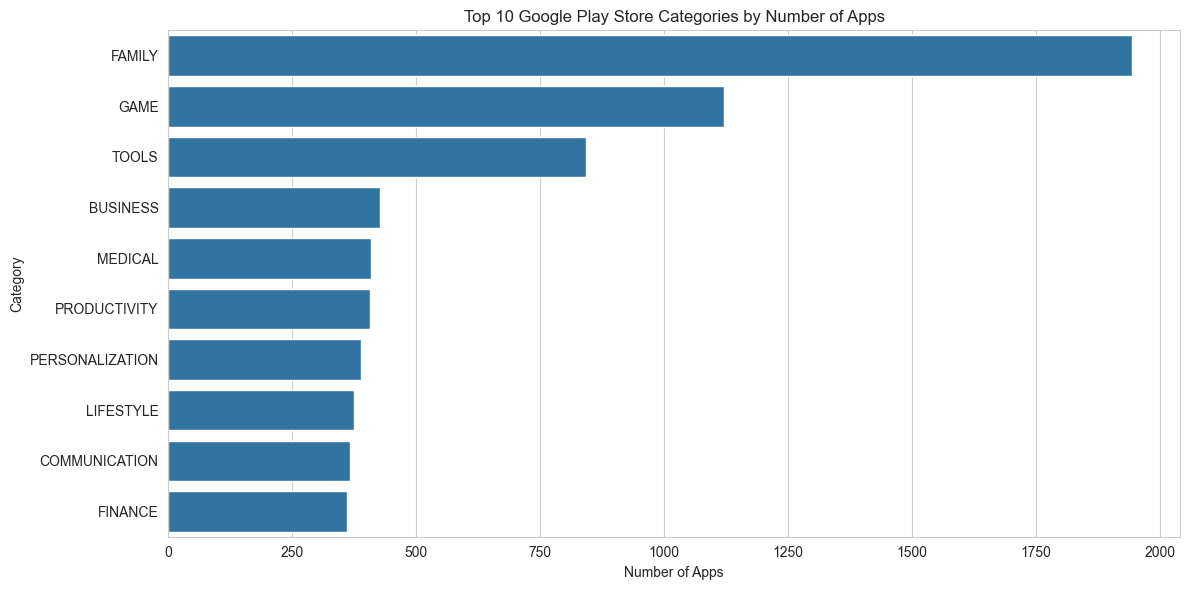

In [24]:
# Count apps in each category
category_counts = apps_clean["Category"].value_counts()

# Display the top 10 categories
print(category_counts.head(10))

# Visualize the top 10 categories
plt.figure(figsize=(12, 6))
sns.barplot(
    x=category_counts.head(10).values,
    y=category_counts.head(10).index
)

plt.title("Top 10 Google Play Store Categories by Number of Apps")
plt.xlabel("Number of Apps")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

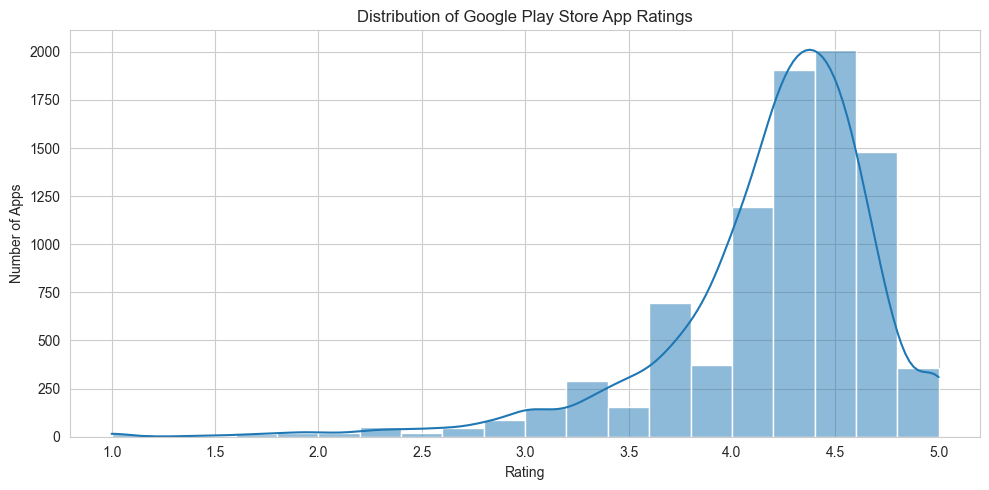

In [25]:
# Distribution of app ratings
plt.figure(figsize=(10, 5))

sns.histplot(
    apps_clean["Rating"].dropna(),
    bins=20,
    kde=True
)

plt.title("Distribution of Google Play Store App Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Apps")
plt.tight_layout()
plt.show()

Type
Free       9592
Paid        765
Unknown       1
Name: count, dtype: int64


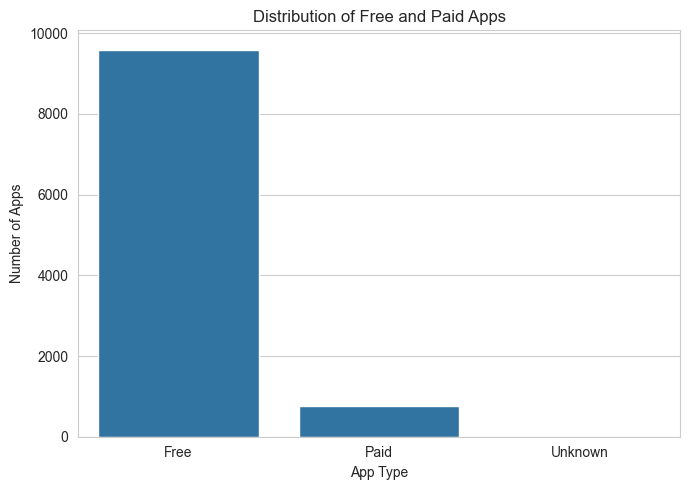

In [26]:
# Count free and paid apps
type_counts = apps_clean["Type"].value_counts()

print(type_counts)

# Plot the distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=apps_clean, x="Type", order=type_counts.index)

plt.title("Distribution of Free and Paid Apps")
plt.xlabel("App Type")
plt.ylabel("Number of Apps")
plt.tight_layout()
plt.show()

                                     App   Installs            Category
                       Google Play Books 1000000000 BOOKS_AND_REFERENCE
Messenger – Text and Video Chat for Free 1000000000       COMMUNICATION
                      WhatsApp Messenger 1000000000       COMMUNICATION
            Google Chrome: Fast & Secure 1000000000       COMMUNICATION
                                   Gmail 1000000000       COMMUNICATION
                                Hangouts 1000000000       COMMUNICATION
Messenger – Text and Video Chat for Free 1000000000       COMMUNICATION
                                Hangouts 1000000000       COMMUNICATION
           Skype - free IM & video calls 1000000000       COMMUNICATION
            Google Chrome: Fast & Secure 1000000000       COMMUNICATION


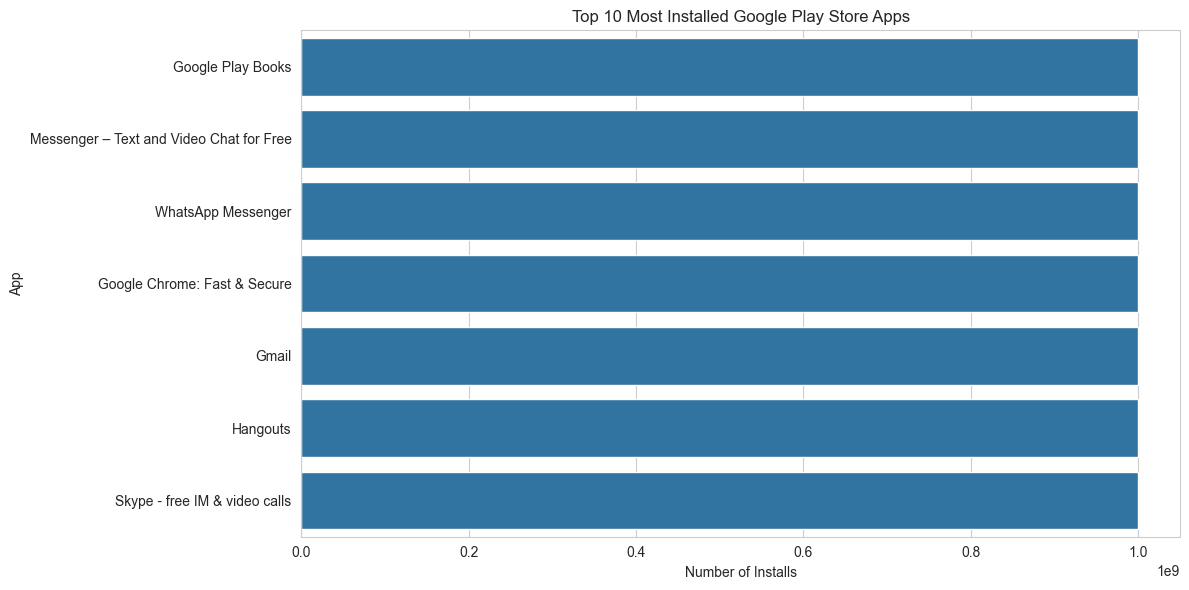

In [27]:
# Top 10 apps by number of installs
top_installed = apps_clean.nlargest(10, "Installs")[["App", "Installs", "Category"]]

print(top_installed.to_string(index=False))

# Visualize the top 10 apps
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_installed,
    x="Installs",
    y="App"
)

plt.title("Top 10 Most Installed Google Play Store Apps")
plt.xlabel("Number of Installs")
plt.ylabel("App")
plt.tight_layout()
plt.show()

                                     App   Installs            Category
                       Google Play Books 1000000000 BOOKS_AND_REFERENCE
Messenger – Text and Video Chat for Free 1000000000       COMMUNICATION
                      WhatsApp Messenger 1000000000       COMMUNICATION
            Google Chrome: Fast & Secure 1000000000       COMMUNICATION
                                   Gmail 1000000000       COMMUNICATION
                                Hangouts 1000000000       COMMUNICATION
Messenger – Text and Video Chat for Free 1000000000       COMMUNICATION
                                Hangouts 1000000000       COMMUNICATION
           Skype - free IM & video calls 1000000000       COMMUNICATION
            Google Chrome: Fast & Secure 1000000000       COMMUNICATION


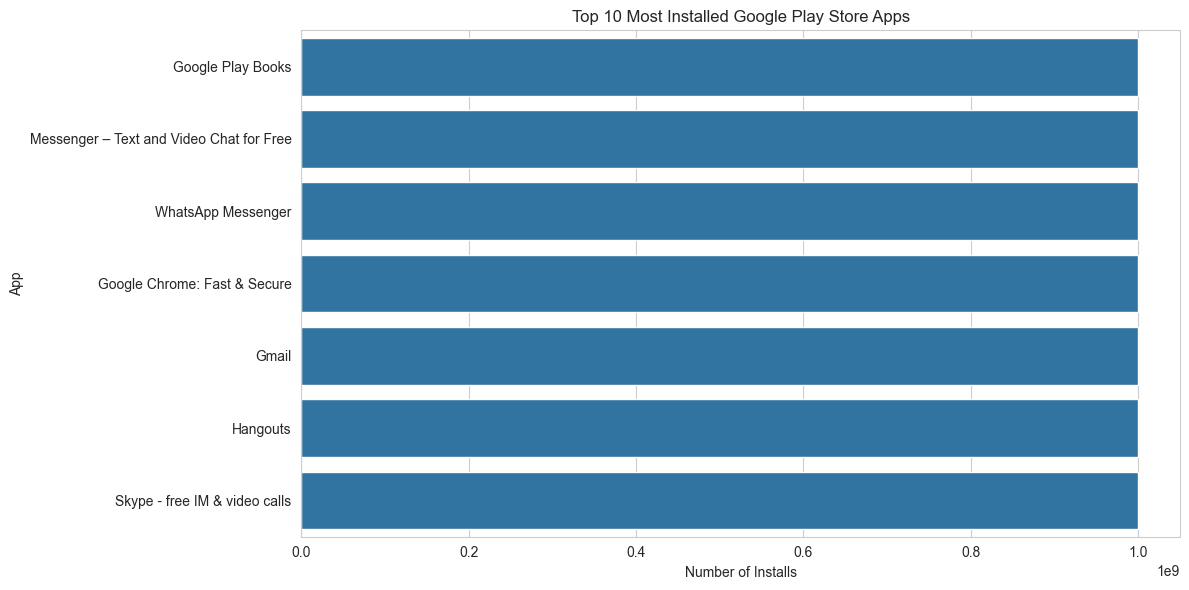

In [28]:
# Top 10 apps by number of installs
top_installed = apps_clean.nlargest(
    10, "Installs"
)[["App", "Installs", "Category"]]

print(top_installed.to_string(index=False))

# Visualize the top 10 apps
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_installed,
    x="Installs",
    y="App"
)

plt.title("Top 10 Most Installed Google Play Store Apps")
plt.xlabel("Number of Installs")
plt.ylabel("App")
plt.tight_layout()
plt.show()

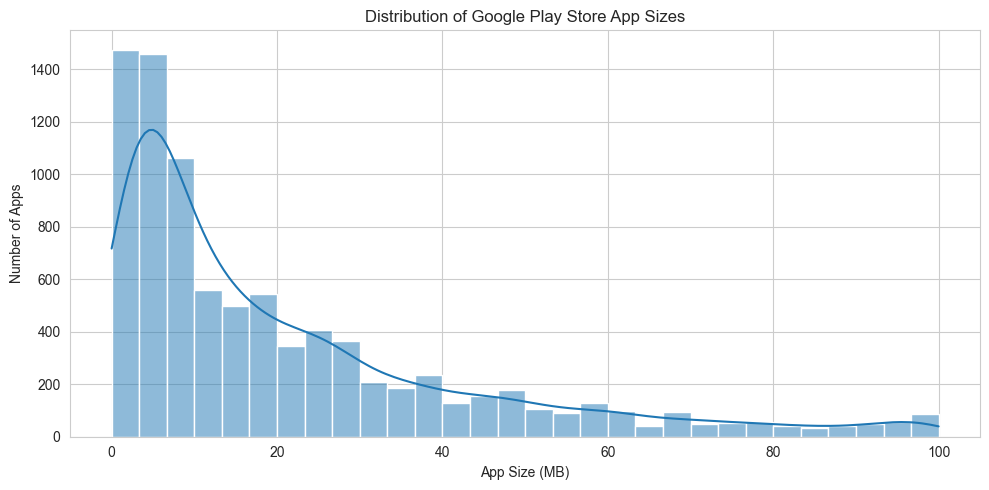

In [29]:
# Distribution of app sizes
plt.figure(figsize=(10, 5))

sns.histplot(
    apps_clean["Size_MB"].dropna(),
    bins=30,
    kde=True
)

plt.title("Distribution of Google Play Store App Sizes")
plt.xlabel("App Size (MB)")
plt.ylabel("Number of Apps")
plt.tight_layout()
plt.show()

Top 10 categories by average rating:
Category
EVENTS                 4.44
EDUCATION              4.38
ART_AND_DESIGN         4.36
BOOKS_AND_REFERENCE    4.35
PERSONALIZATION        4.33
PARENTING              4.30
GAME                   4.28
BEAUTY                 4.28
HEALTH_AND_FITNESS     4.26
SOCIAL                 4.25
Name: Rating, dtype: float64


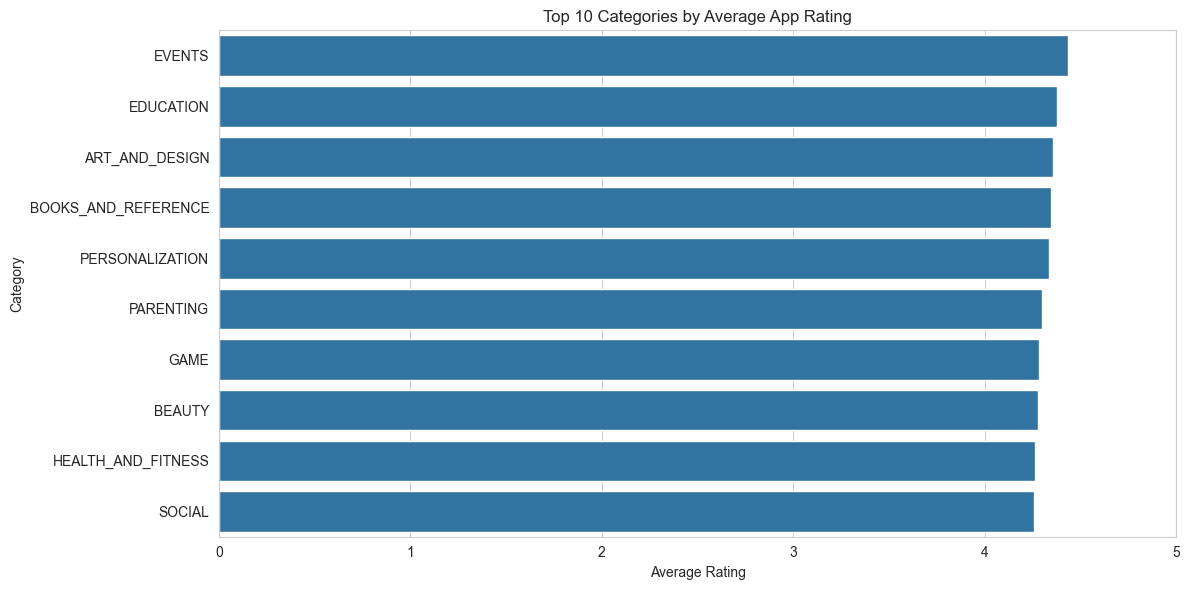

In [30]:
# Calculate average rating for each category
avg_rating_category = (
    apps_clean.groupby("Category")["Rating"]
    .mean()
    .sort_values(ascending=False)
)

print("Top 10 categories by average rating:")
print(avg_rating_category.head(10).round(2))

# Visualize the top 10 categories
plt.figure(figsize=(12, 6))

sns.barplot(
    x=avg_rating_category.head(10).values,
    y=avg_rating_category.head(10).index
)

plt.title("Top 10 Categories by Average App Rating")
plt.xlabel("Average Rating")
plt.ylabel("Category")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

Review sentiment counts:
Sentiment
Positive    19015
Negative     6321
Neutral      4356
Name: count, dtype: int64


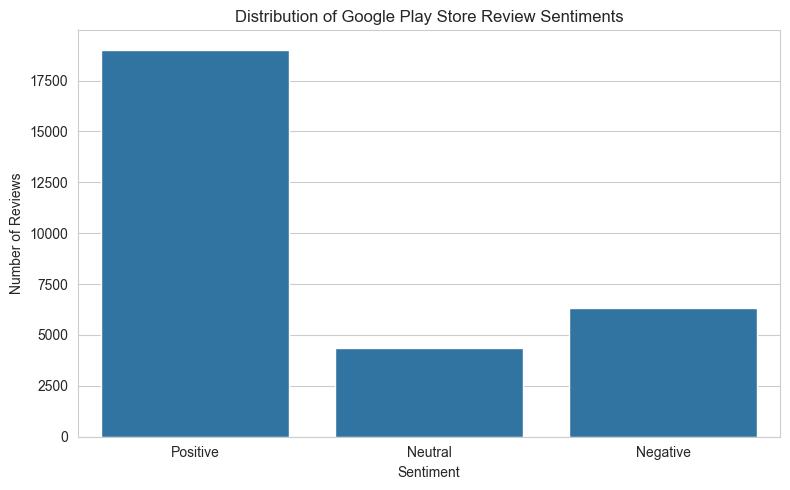

In [31]:
# Count reviews by sentiment
sentiment_counts = reviews_for_sentiment["Sentiment"].value_counts()

print("Review sentiment counts:")
print(sentiment_counts)

# Plot sentiment distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=reviews_for_sentiment,
    x="Sentiment",
    order=["Positive", "Neutral", "Negative"]
)

plt.title("Distribution of Google Play Store Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

**7. App Size vs. Number of Install**

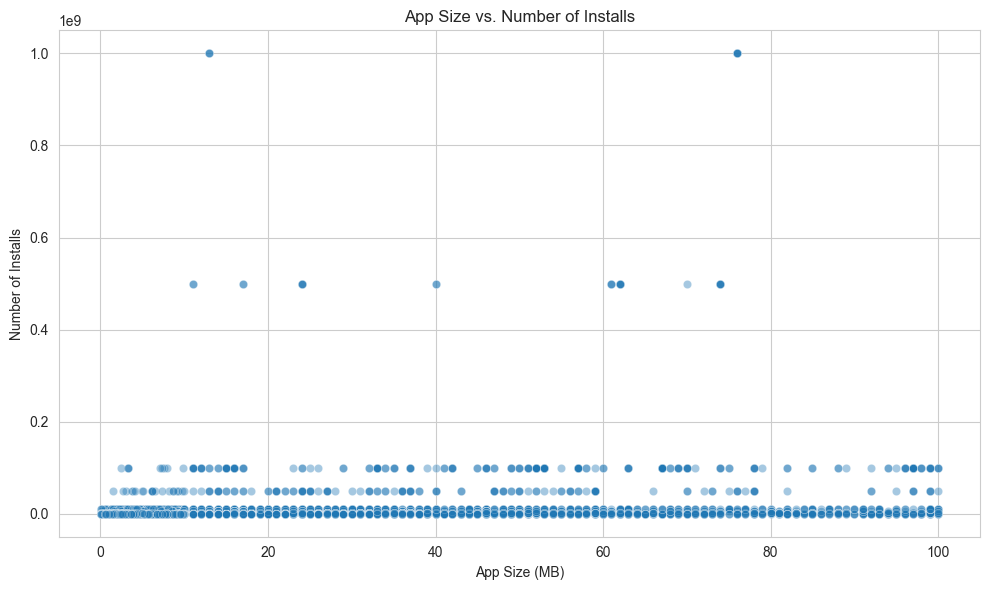

In [32]:
size_installs = apps_clean.dropna(
    subset=["Size_MB", "Installs"]
).copy()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=size_installs,
    x="Size_MB",
    y="Installs",
    alpha=0.4
)

plt.title("App Size vs. Number of Installs")
plt.xlabel("App Size (MB)")
plt.ylabel("Number of Installs")
plt.tight_layout()
plt.show()

In [33]:
correlation = size_installs["Size_MB"].corr(
    size_installs["Installs"]
)

print("Correlation between app size and installs:", round(correlation, 3))

Correlation between app size and installs: 0.169


### Observation: App Size vs. Installs

The correlation between app size and number of installs is **0.169**, indicating a weak positive linear relationship. This suggests that app size has little linear association with installation counts in this dataset. Other factors, such as app category, popularity, and functionality, may also influence installs. Correlation does not imply causation.

**8. Paid-App Pricing Analysis**

In [34]:
# Compare free and paid apps
print("Free vs Paid App Counts:")
print(apps_clean["Type"].value_counts())

# Get paid apps with valid prices
paid_apps = apps_clean[
    (apps_clean["Type"] == "Paid") &
    (apps_clean["Price"] > 0)
].copy()

print("\nNumber of paid apps:", len(paid_apps))
print("\nPrice summary:")
print(paid_apps["Price"].describe())

Free vs Paid App Counts:
Type
Free       9592
Paid        765
Unknown       1
Name: count, dtype: int64

Number of paid apps: 765

Price summary:
count    765.000000
mean      13.955556
std       58.406966
min        0.990000
25%        1.490000
50%        2.990000
75%        4.990000
max      400.000000
Name: Price, dtype: float64


**9. Visualize Paid-App Prices**

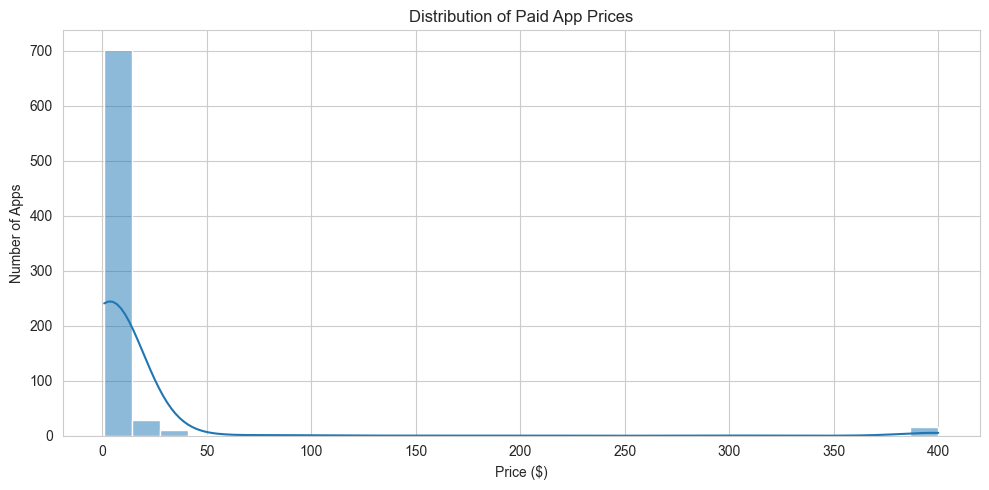

In [35]:
# Distribution of paid app prices
plt.figure(figsize=(10, 5))

sns.histplot(
    data=paid_apps,
    x="Price",
    bins=30,
    kde=True
)

plt.title("Distribution of Paid App Prices")
plt.xlabel("Price ($)")
plt.ylabel("Number of Apps")
plt.tight_layout()
plt.show()

Most paid apps are priced at the lower end, with a median price of $2.99. A small number of expensive apps, reaching $400, pull the average price upward and create a right-skewed distribution.

**10. TextBlob sentiment analysis**

In [36]:
try:
    from textblob import TextBlob
    print("TextBlob is available.")
except ImportError:
    print("TextBlob is not installed.")

TextBlob is available.


In [37]:
reviews_for_sentiment["TextBlob_Polarity"] = reviews_for_sentiment[
    "Translated_Review"
].apply(lambda text: TextBlob(text).sentiment.polarity)

def classify_sentiment(polarity):
    if polarity > 0:
        return "Positive"
    elif polarity < 0:
        return "Negative"
    else:
        return "Neutral"

reviews_for_sentiment["TextBlob_Sentiment"] = (
    reviews_for_sentiment["TextBlob_Polarity"].apply(classify_sentiment)
)

print(reviews_for_sentiment["TextBlob_Sentiment"].value_counts())

TextBlob_Sentiment
Positive    19014
Negative     6322
Neutral      4356
Name: count, dtype: int64


### Sentiment Analysis using TextBlob

Polarity analysis of user reviews was done using TextBlob where each review is classified as positive, negative, or neutral. From a total of 29,692 reviews, there were 19,014 positive reviews, 6,322 negative reviews, and 4,356 neutral reviews. Positive reviews were the majority in this case.

In [38]:
app_categories = apps_clean[["App", "Category"]].drop_duplicates()

reviews_with_category = reviews_for_sentiment.merge(
    app_categories,
    on="App",
    how="left"
)

print("Reviews with category:", reviews_with_category.shape)
print("Missing categories:", reviews_with_category["Category"].isna().sum())

Reviews with category: (31081, 8)
Missing categories: 1442


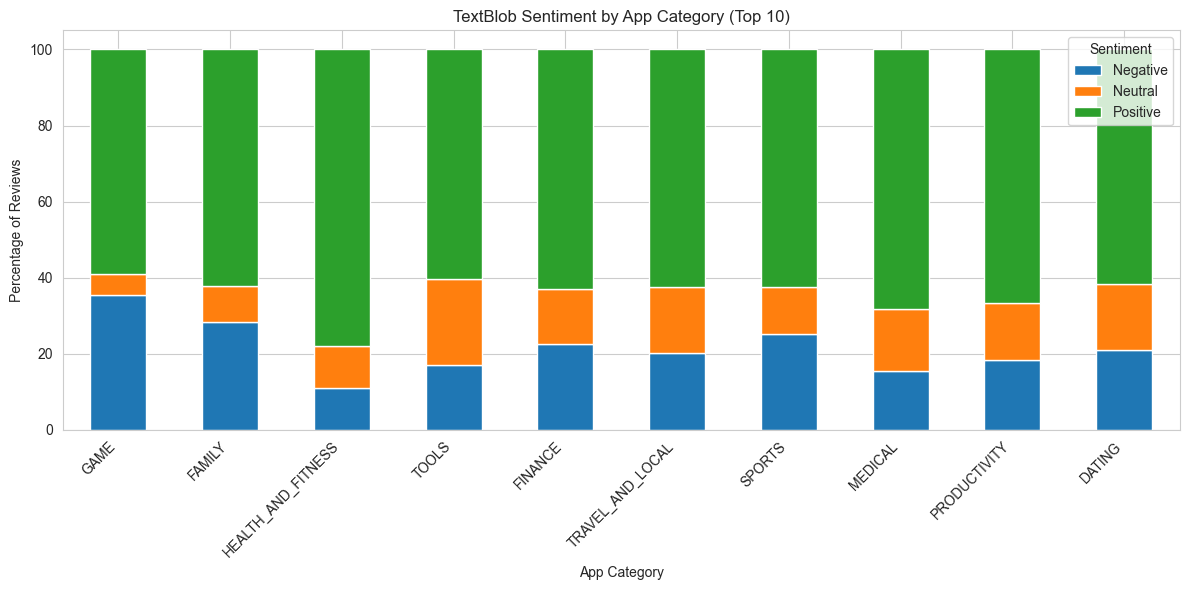

In [39]:
reviews_with_category = reviews_with_category.dropna(
    subset=["Category"]
).copy()

sentiment_by_category = pd.crosstab(
    reviews_with_category["Category"],
    reviews_with_category["TextBlob_Sentiment"],
    normalize="index"
) * 100

top_categories = (
    reviews_with_category["Category"]
    .value_counts()
    .head(10)
    .index
)

sentiment_by_category.loc[top_categories].plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("TextBlob Sentiment by App Category (Top 10)")
plt.xlabel("App Category")
plt.ylabel("Percentage of Reviews")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

### Sentiment by App Category

TextBlob sentiment analysis shows that positive reviews form the largest share across all 10 app categories. Health & Fitness has the highest proportion of positive sentiment among the categories shown, while Game and Family have comparatively larger shares of negative reviews. These differences may help developers identify areas for improvement and understand user feedback across app categories.

In [40]:
try:
    import plotly.express as px
    print("Plotly is available.")
except ImportError:
    print("Plotly is not installed.")

Plotly is not installed.


## Conclusion

This project analyzed the Google Play Store dataset to understand app categories, ratings, installations, pricing, and user sentiment.

- **App Categories:** Family, Game, and Tools were among the categories with the highest numbers of apps.
- **Ratings:** Most apps had ratings between 4.0 and 4.7, indicating generally favorable ratings among rated apps.
- **Free vs. Paid Apps:** Free apps greatly outnumbered paid apps in the dataset.
- **App Size and Installs:** The correlation was 0.169, indicating a weak positive linear relationship between app size and installations.
- **Paid App Pricing:** The median price of paid apps was $2.99, while a few expensive apps increased the average price.
- **User Sentiment:** TextBlob classified most analyzed reviews as positive, followed by negative and neutral reviews.
- **Sentiment by Category:** Positive sentiment was the largest group across the ten categories analyzed, although the proportions of negative and neutral reviews varied.

### Recommendations for Developers

Developers should focus on app quality, user feedback, suitable pricing, and the needs of their target category. They should also investigate negative reviews to identify opportunities for improvement.

Overall, the analysis provides insights into app market patterns and user opinions that can support data-informed development decisions.